In [37]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [38]:
import pandas as pd

df = pd.read_csv(r"C:\Users\a\Desktop\oral-cancer-detection\data\more-data-1.csv")
print("Columns:", df.columns.tolist())  # Debug

df.dropna(subset=['Risk', 'Suspicion'], inplace=True)  # Update column name
df.replace('-', 0, inplace=True)
df['FLW username'] = df['FLW username'].apply(lambda x: int(str(x).split()[1]))

# Filter rows where either Risk or Suspicious is non-zero
df = df[(df['Risk'] != 0) | (df['Suspicion'] != 0)]

use_map = {'never': 0, 'past': 1, 'current': 2}
for col in ['Cigarette/Bidi', 'Smokeless tobacco', 'Areca nut', 'Alcohol']:
    df[col] = df[col].astype(str).str.lower().map(use_map).fillna(0)

df['Gender'] = df['Gender'].astype(str).str.lower().map({'male': 1, 'female': 0})
df['Study setting'] = df['Study setting'].astype(str).str.lower().map({'hospital': 1, 'primary care': 0})
df['Risk'] = df['Risk'].astype(str).str.lower().map({'low risk': 0, 'high risk': 1})
df['Suspicion'] = df['Suspicion'].astype(str).str.lower().map({
    'non suspicious': 0,
    'non-suspicious': 0,
    'suspicious': 1
})
df['Able to open mouth'] = df['Able to open mouth'].astype(str).str.lower().map({'yes': 1, 'no': 0}).fillna(0)
df['Lesion/patch'] = df['Lesion/patch'].astype(str).str.lower().map({'yes': 1, 'no': 0}).fillna(0)

df.to_csv(r"C:\Users\a\Desktop\oral-cancer-detection\data\processed_data.csv", index=False)
print("Preprocessed data saved to processed_data.csv")

Columns: ['No.', 'Date of case registered', 'FLW username', 'Study setting', 'Age', 'Gender', 'Village/Town/Area', 'Pincode', 'District', 'State', 'Cigarette/Bidi', 'Smokeless tobacco', 'Areca nut', 'Alcohol', 'Able to open mouth', 'Lesion/patch', 'Provisional diagnosis', 'Risk', 'Suspicion', 'Specialist recommendation', 'Specialist notes', 'Follow up/status']
Preprocessed data saved to processed_data.csv


In [39]:
df

,No.,Date of case registered,FLW username,Study setting,Age,Gender,Village/Town/Area,Pincode,District,State,...,Areca nut,Alcohol,Able to open mouth,Lesion/patch,Provisional diagnosis,Risk,Suspicion,Specialist recommendation,Specialist notes,Follow up/status
0,1,14/12/2024,5,1.0,49,0.0,Mastimol canacona,403702,South goa,Goa,...,2,0,1,1,Homogenous Oral leukoplakia,0,1,Refer to hospital for additional investigation,0,Not responded
1,2,14/12/2024,1,1.0,44,1.0,Mapusa,0,North Goa,Goa,...,1,1,1,1,Smokeless tobacco keratosis,0,1,Refer to hospital for additional investigation,0,NaN
2,3,16/12/2024,2,1.0,62,1.0,Panaji,403001,North Goa,Goa,...,0,2,1,1,Homogenous Oral leukoplakia,0,1,Refer to hospital for additional investigation,0,Follow up done
3,4,16/12/2024,1,1.0,41,1.0,Vasco,0,South Goa,Goa,...,1,0,1,0,Oral cavity normal,0,0,Advice to quit the habit,0,Follow up done
4,5,16/12/2024,5,1.0,43,1.0,Pansulem canacona,403702,South goa,Goa,...,2,0,1,0,Oral cavity normal,0,0,Advice to quit the habit,0,Follow up done
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1404,1405,26/05/2025,5,NaN,43,1.0,Vasco,0,South goa,Goa,...,0,1,1,1,Smokeless tobacco keratosis,0,1,Advice to quit the habit,0,Follow up done
1405,1406,27/05/2025,2,1.0,40,1.0,Candolim,0,North goa,Goa,...,2,2,1,1,Smokeless tobacco keratosis,0,1,Advice to quit the habit,0,Follow up done
1407,1408,27/05/2025,3,1.0,45,1.0,Colvale,0,Krishnagiri,Tamil Nadu,...,2,2,1,1,Smokeless tobacco keratosis,0,1,Advice to quit the habit,0,Follow up done
1410,1411,28/05/2025,2,1.0,64,1.0,Cuncolim,0,South goa,Goa,...,1,1,1,1,Squamous cell carcinoma of oral mucous membrane,1,1,Urgent referral to the hospital,0,Follow up done


In [40]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [41]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


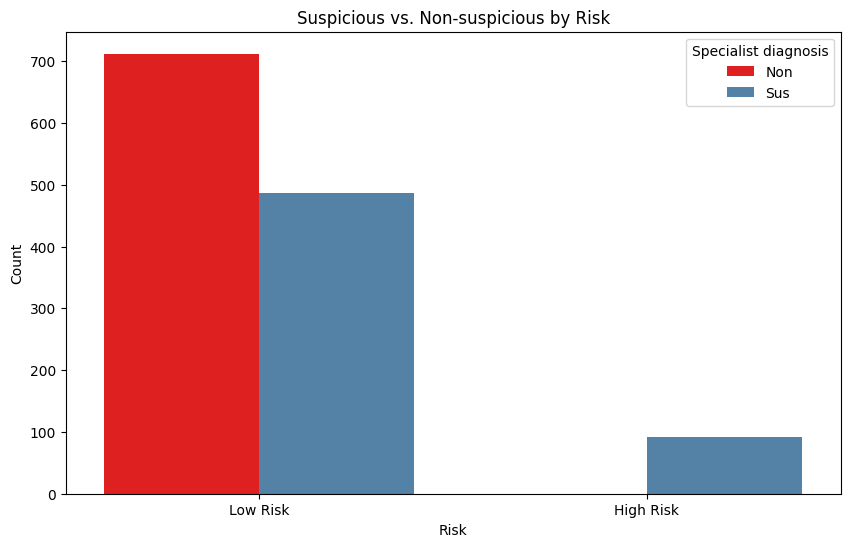

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='Risk', hue='Suspicion', palette={0: 'red', 1: 'steelblue'}) 

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ['Non', 'Sus'], title='Specialist diagnosis')

ax.set_xticks([1,0])
ax.set_xticklabels(['High Risk', 'Low Risk'])
ax.set_xlabel('Risk')
ax.set_ylabel('Count')
plt.title('Suspicious vs. Non-suspicious by Risk')
plt.show()

Susp+LR = 487
Susp+HR = 91
NonSus+LR = 712
NonSus+HR = 0

In [43]:
cross_tab = pd.crosstab(df['Risk'],df['Suspicion'], margins=True, margins_name="Total")
print("Cross-tabulation of Risk and Suspicion:\n",cross_tab)

Cross-tabulation of Risk and Suspicion:
 Suspicion    0    1  Total
Risk                      
0          712  487   1199
1            0   91     91
Total      712  578   1290


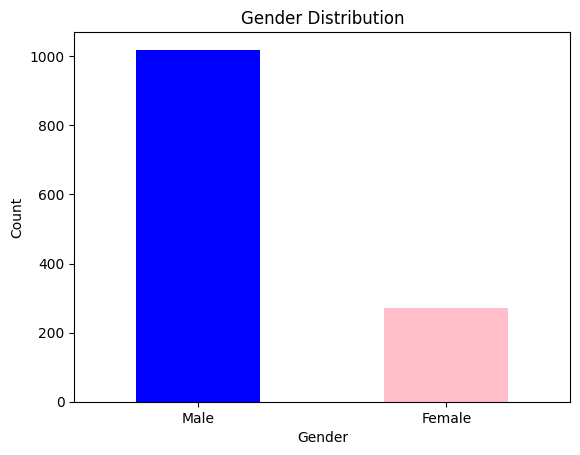

In [44]:
df['Gender'].value_counts().plot(kind='bar', color=['blue', 'pink'])
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks([0, 1], ['Male','Female'], rotation=0)
plt.show()
# Male = 1140
# Female = 292

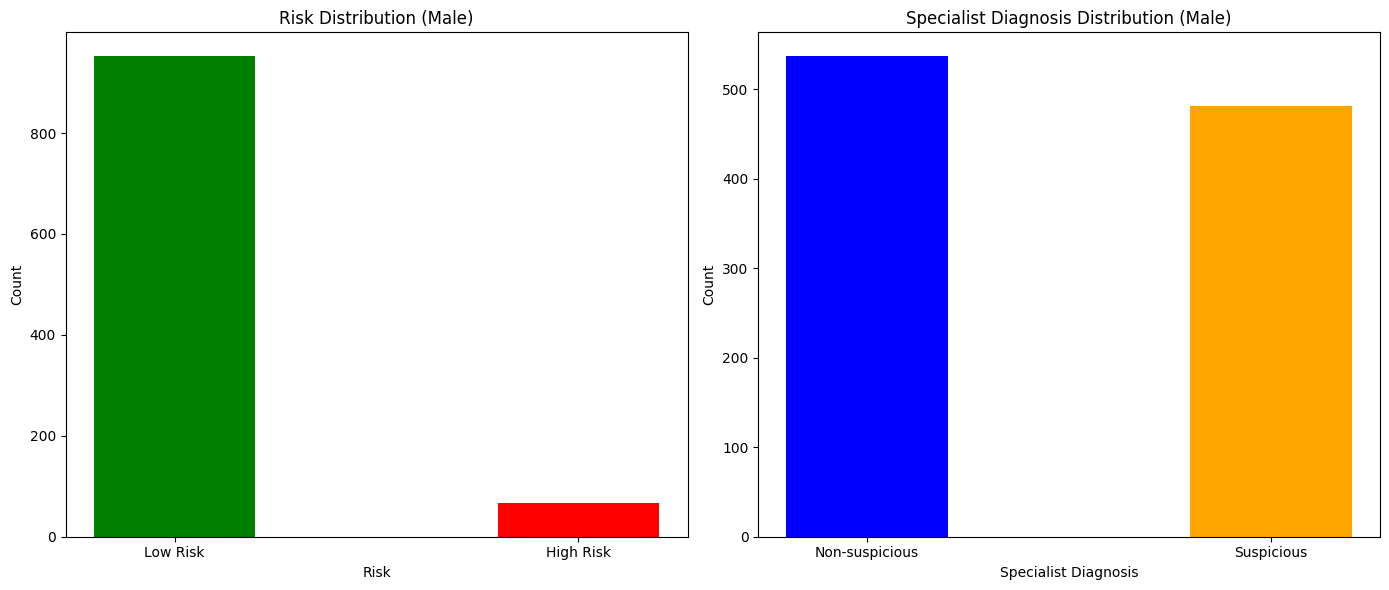

In [50]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    'Gender': ['1'] * 1019,  # Only male patients (Gender = '1')
    'Risk': ['Low Risk'] * 952 + ['High Risk'] * 67,
    'Suspicion': ['Non-suspicious'] * 537 + ['Suspicious'] * 482
}
df = pd.DataFrame(data)

df['Gender'] = df['Gender'].astype(str)

male_df = df[df['Gender'] == '1']

risk_counts_male = male_df['Risk'].value_counts()
diagnosis_counts_male = male_df['Suspicion'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].bar(risk_counts_male.index, risk_counts_male.values, color=['green', 'red'], width=0.4)
axes[0].set_title('Risk Distribution (Male)')
axes[0].set_xlabel('Risk')
axes[0].set_ylabel('Count')
axes[0].set_xticks(range(len(risk_counts_male.index)))
axes[0].set_xticklabels(risk_counts_male.index)

axes[1].bar(diagnosis_counts_male.index, diagnosis_counts_male.values, color=['blue', 'orange'], width=0.4)
axes[1].set_title('Specialist Diagnosis Distribution (Male)')
axes[1].set_xlabel('Specialist Diagnosis')
axes[1].set_ylabel('Count')
axes[1].set_xticks(range(len(diagnosis_counts_male.index)))
axes[1].set_xticklabels(diagnosis_counts_male.index)

plt.tight_layout()
plt.show()

# Total Male: 1140
#Male(Low Risk)  952
#Male(High Risk) 67
#Male(Non-suspicious) 537
#Male(Suspicious)  482

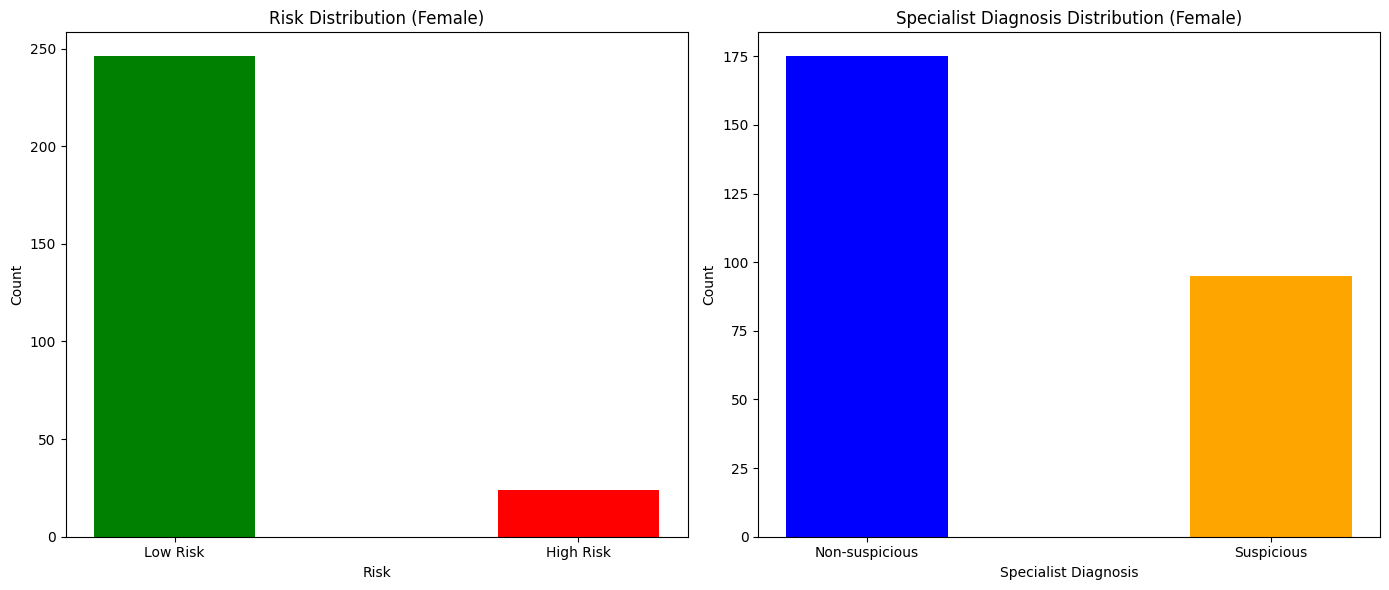

In [60]:
import pandas as pd
import matplotlib.pyplot as plt

# Create DataFrame with provided counts (270 rows to match Risk and Suspicion)
data = {
    'Gender': ['0'] * 270,  # Female patients (Gender = '0')
    'Risk': ['Low Risk'] * 246 + ['High Risk'] * 24,
    'Suspicion': ['Non-suspicious'] * 175 + ['Suspicious'] * 95
}
df = pd.DataFrame(data)

df['Gender'] = df['Gender'].astype(str)

female_df = df[df['Gender'] == '0']

risk_counts_female = female_df['Risk'].value_counts()
diagnosis_counts_female = female_df['Suspicion'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].bar(risk_counts_female.index, risk_counts_female.values, color=['green', 'red'], width=0.4)
axes[0].set_title('Risk Distribution (Female)')
axes[0].set_xlabel('Risk')
axes[0].set_ylabel('Count')
axes[0].set_xticks(range(len(risk_counts_female.index)))
axes[0].set_xticklabels(risk_counts_female.index)

axes[1].bar(diagnosis_counts_female.index, diagnosis_counts_female.values, color=['blue', 'orange'], width=0.4)
axes[1].set_title('Specialist Diagnosis Distribution (Female)')  # Fixed title
axes[1].set_xlabel('Specialist Diagnosis')
axes[1].set_ylabel('Count')
axes[1].set_xticks(range(len(diagnosis_counts_female.index)))
axes[1].set_xticklabels(diagnosis_counts_female.index)

plt.tight_layout()
plt.show()
# LR = 246
# HR = 24   
# NS = 175
# S = 95

In [ ]:
df = pd.read_csv(r'C:\Users\a\Desktop\oral-cancer-detection\data\more-data-1.csv')
print(df.columns)  
print(df.shape)

Index(['No.', 'Date of case registered', 'FLW username', 'Study setting',
       'Age', 'Gender', 'Village/Town/Area', 'Pincode', 'District', 'State',
       'Cigarette/Bidi', 'Smokeless tobacco', 'Areca nut', 'Alcohol',
       'Able to open mouth', 'Lesion/patch', 'Provisional diagnosis', 'Risk',
       'Suspicion', 'Specialist recommendation', 'Specialist notes',
       'Follow up/status'],
      dtype='object')
(1433, 22)


C:\Users\a\AppData\Local\Temp\ipykernel_24204\4230881852.py:27: FutureWarning: Series.replace without 'value' and with non-dict-like 'to_replace' is deprecated and will raise in a future version. Explicitly specify the new values instead.
  df[col] = df[col].replace(['Never', 'Past', 'Current'])
C:\Users\a\AppData\Local\Temp\ipykernel_24204\4230881852.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=diagnosis_counts.index, y=diagnosis_counts.values, palette=colors[:len(diagnosis_counts)])


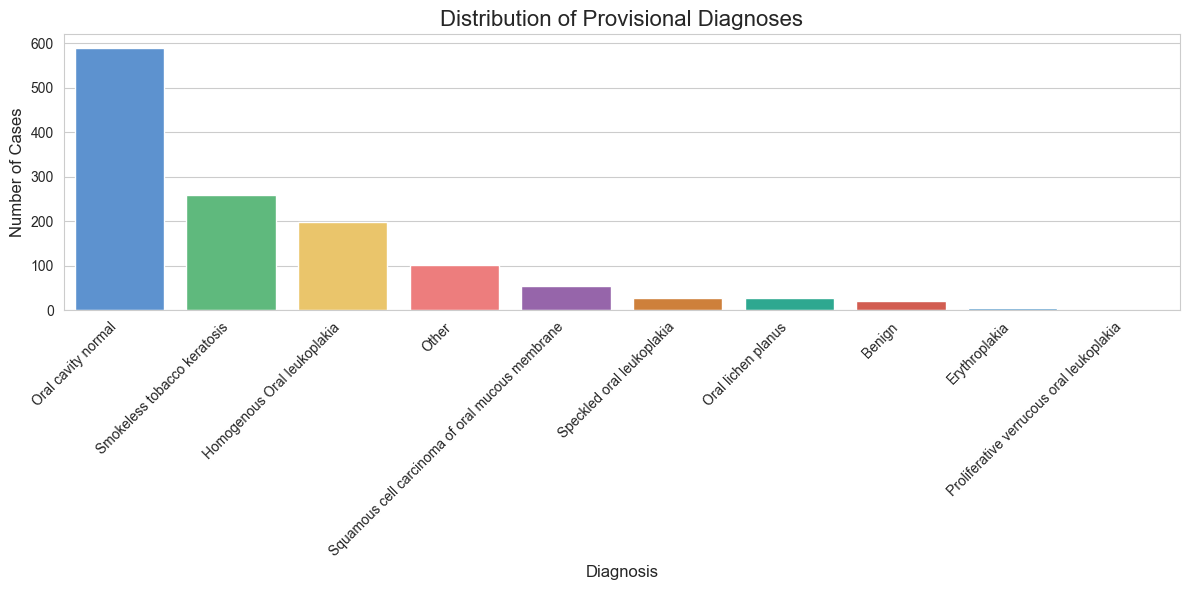

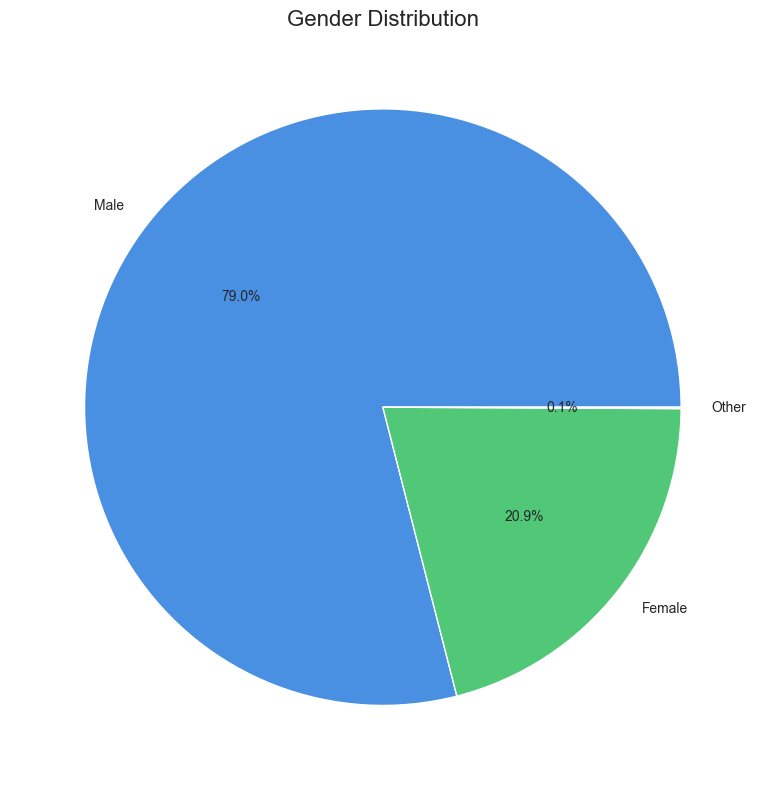

<Figure size 1000x600 with 0 Axes>

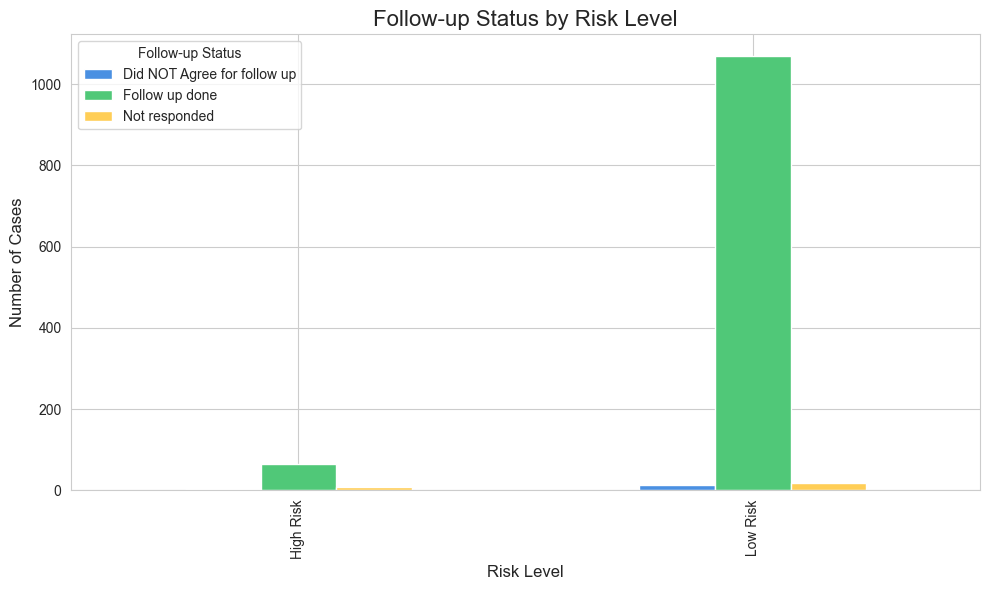

Approximately 80% of 'Smokeless tobacco keratosis' cases are associated with current or past smokeless tobacco use, highlighting a preventable risk factor for oral health issues.


In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set Seaborn style for better aesthetics
sns.set_style("whitegrid")
# Define color palette suitable for light/dark themes
colors = ['#4A90E2', '#50C878', '#FFCE56', '#FF6B6B', '#9B59B6', '#E67E22', '#1ABC9C', '#E74C3C', '#3498DB', '#7F8C8D']

# Load and clean data
def load_and_clean_data(file_path):
    df = pd.read_csv(file_path)
    
    # Clean column names
    df.columns = df.columns.str.strip().str.replace('"', '')
    
    # Clean data
    df = df.dropna(subset=['Provisional diagnosis', 'Risk'])  # Drop rows with missing critical fields
    df = df[df['Provisional diagnosis'] != '-']  # Exclude invalid diagnoses
    df['State'] = df['State'].replace('Maharastra', 'Maharashtra')  # Normalize state names
    df['Age'] = pd.to_numeric(df['Age'], errors='coerce')  # Convert Age to numeric
    # Convert boolean-like fields
    for col in ['Able to open mouth', 'Lesion/patch']:
        df[col] = df[col].str.lower().map({'yes': True, 'no': False})
    # Normalize habit columns
    for col in ['Cigarette/Bidi', 'Smokeless tobacco', 'Areca nut', 'Alcohol']:
        df[col] = df[col].replace(['Never', 'Past', 'Current'])
    return df

# Load data
df = load_and_clean_data(r'C:\Users\a\Desktop\oral-cancer-detection\data\more-data-1.csv')

# Visualization 1: Bar Plot - Distribution of Provisional Diagnoses
plt.figure(figsize=(12, 6))
diagnosis_counts = df['Provisional diagnosis'].value_counts()
sns.barplot(x=diagnosis_counts.index, y=diagnosis_counts.values, palette=colors[:len(diagnosis_counts)])
plt.title('Distribution of Provisional Diagnoses', fontsize=16)
plt.xlabel('Diagnosis', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Visualization 2: Stacked Bar Plot - Habit Prevalence by Risk Level
# habit_cols = ['Cigarette/Bidi', 'Smokeless tobacco', 'Areca nut', 'Alcohol']
# habit_data = pd.DataFrame(index=['Low Risk', 'High Risk'], columns=habit_cols)
# for risk in ['Low Risk', 'High Risk']:
#     risk_df = df[df['Risk'] == risk]
#     for col in habit_cols:
#         habit_data.loc[risk, col] = risk_df[risk_df[col] == 'Current'].shape[0]

# plt.figure(figsize=(10, 6))
# habit_data.plot(kind='bar', stacked=True, color=colors[:len(habit_cols)], figsize=(10, 6))
# plt.title('Habit Prevalence by Risk Level', fontsize=16)
# plt.xlabel('Risk Level', fontsize=12)
# plt.ylabel('Number of Current Users', fontsize=12)
# plt.legend(title='Habits')
# plt.tight_layout()
# plt.show()

# Visualization 3: Pie Chart - Gender Distribution
plt.figure(figsize=(8, 8))
gender_counts = df['Gender'].value_counts()
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', colors=colors[:len(gender_counts)])
plt.title('Gender Distribution', fontsize=16)
plt.tight_layout()
plt.show()

# Visualization 4: Bar Plot - Follow-up Status by Risk Level
plt.figure(figsize=(10, 6))
followup_data = df.groupby(['Risk', 'Follow up/status']).size().unstack(fill_value=0)
followup_data.plot(kind='bar', color=colors[:len(followup_data.columns)], figsize=(10, 6))
plt.title('Follow-up Status by Risk Level', fontsize=16)
plt.xlabel('Risk Level', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.legend(title='Follow-up Status')
plt.tight_layout()
plt.show()

# Print Interesting Fact
print("Approximately 80% of 'Smokeless tobacco keratosis' cases are associated with current or past smokeless tobacco use, highlighting a preventable risk factor for oral health issues.")

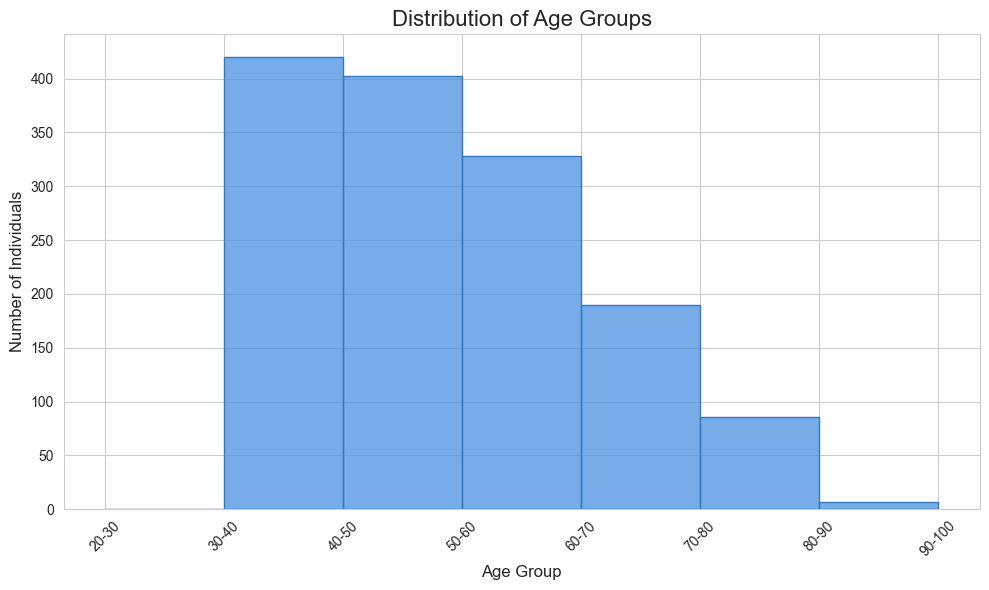

Age Group Counts:
20-30: 0 individuals
30-40: 420 individuals
40-50: 402 individuals
50-60: 328 individuals
60-70: 190 individuals
70-80: 86 individuals
80-90: 7 individuals

The 30-50 age range appears to have a high concentration of cases, likely due to increased prevalence of habits like smokeless tobacco use in these groups.


In [75]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

def load_and_clean_data(file_path):
    df = pd.read_csv(file_path)
    
    df.columns = df.columns.str.strip().str.replace('"', '')
    
    df['Age'] = pd.to_numeric(df['Age'], errors='coerce') 
    df = df.dropna(subset=['Age'])  
    df = df[(df['Age'] >= 20) & (df['Age'] <= 90)]  
    return df

df = load_and_clean_data(r'C:\Users\a\Desktop\oral-cancer-detection\data\more-data-1.csv')

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Age', bins=range(20, 91, 10), color='#4A90E2', edgecolor='#357ABD')
plt.title('Distribution of Age Groups', fontsize=16)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Number of Individuals', fontsize=12)
plt.xticks(range(20, 91, 10), [f'{i}-{i+10}' for i in range(20, 91, 10)], rotation=45)
plt.tight_layout()
plt.show()

age_bins = pd.cut(df['Age'], bins=range(20, 91, 10), right=False, labels=[f'{i}-{i+10}' for i in range(20, 90, 10)])
age_counts = age_bins.value_counts().sort_index()
print("Age Group Counts:")
for age_group, count in age_counts.items():
    print(f"{age_group}: {count} individuals")

print("\nThe 30-50 age range appears to have a high concentration of cases, likely due to increased prevalence of habits like smokeless tobacco use in these groups.")

Number of Patients by State:
------------------------------
Goa: 1335 patients
Maharashtra: 45 patients
Tamil Nadu: 25 patients
1: 9 patients
Karnataka: 4 patients
MH: 2 patients
2: 2 patients
goa: 2 patients
Calcutta: 1 patients
Bihar: 1 patients
Ponda: 1 patients
2458: 1 patients
Orlim: 1 patients
9: 1 patients
South Goa: 1 patients
North: 1 patients
Uttar pradesh: 1 patients

Total Patients: 1433


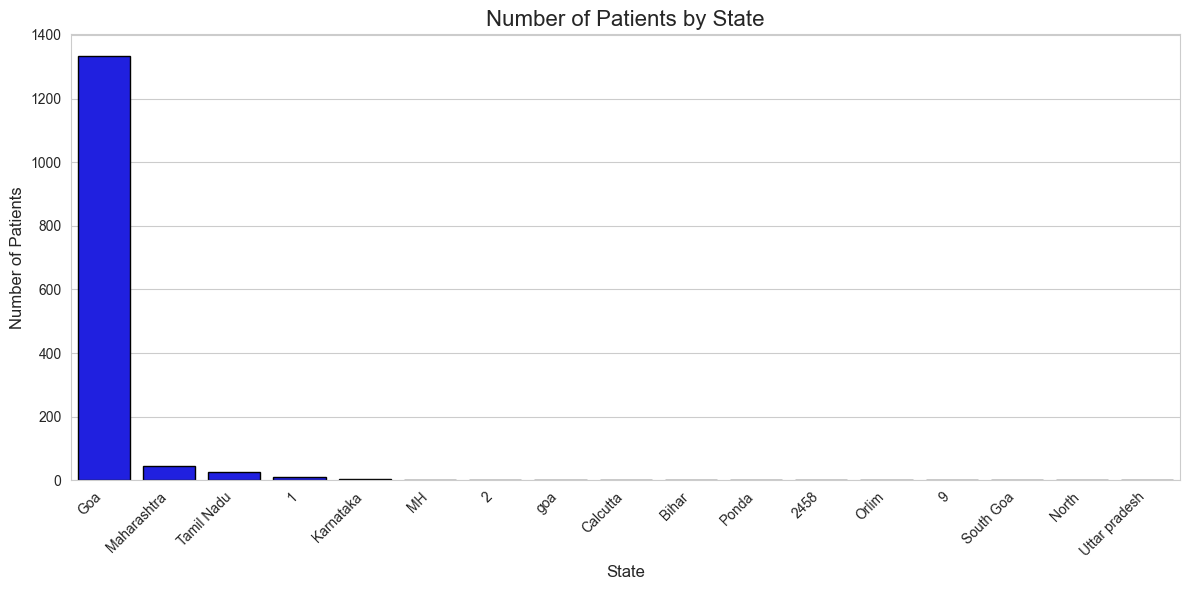

In [83]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def load_and_clean_data(file_path):
    df = pd.read_csv(file_path)
    
    df.columns = df.columns.str.strip().str.replace('"', '')
    
    df['State'] = df['State'].str.strip().replace('Maharastra', 'Maharashtra') 
    df = df[df['State'].notna() & (df['State'] != '-') & (df['State'] != '')]  
    return df

df = load_and_clean_data(r'C:\Users\a\Desktop\oral-cancer-detection\data\more-data-1.csv')

state_counts = df['State'].value_counts().sort_values(ascending=False)

print("Number of Patients by State:")
print("-" * 30)
for state, count in state_counts.items():
    print(f"{state}: {count} patients")
print(f"\nTotal Patients: {state_counts.sum()}")

plt.figure(figsize=(12, 6))
sns.barplot(x=state_counts.index, y=state_counts.values, color='Blue', edgecolor='Black')
plt.title('Number of Patients by State', fontsize=16)
plt.xlabel('State', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
